Importing all required libraries

In [141]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
# Model Selection & Tuning
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV

# Preprocessing & Pipeline Construction
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Model Families
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

# Evaluation Metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

Data Preprocessing 

In [100]:
df=pd.read_csv('ai4i2020_messy.csv')

In [101]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551.0,42.8,0.0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408.0,46.3,3.0,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498.0,49.4,5.0,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433.0,39.5,7.0,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408.0,40.0,9.0,0,0,0,0,0,0


In [102]:
df.shape

(10150, 14)

In [103]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10150 entries, 0 to 10149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10150 non-null  int64  
 1   Product ID               10150 non-null  str    
 2   Type                     9850 non-null   str    
 3   Air temperature [K]      9851 non-null   float64
 4   Process temperature [K]  9850 non-null   float64
 5   Rotational speed [rpm]   9850 non-null   float64
 6   Torque [Nm]              9850 non-null   float64
 7   Tool wear [min]          9851 non-null   float64
 8   Machine failure          10150 non-null  int64  
 9   TWF                      10150 non-null  int64  
 10  HDF                      10150 non-null  int64  
 11  PWF                      10150 non-null  int64  
 12  OSF                      10150 non-null  int64  
 13  RNF                      10150 non-null  int64  
dtypes: float64(5), int64(7), str(2)
m

In [104]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10150.000000,9851.000000,9850.000000,9850.000000,9850.000000,9851.000000,10150.000000,10150.000000,10150.000000,10150.000000,10150.000000,10150.000000
mean,5003.092118,300.536504,310.007147,1556.271472,40.414904,138.144452,0.033793,0.004532,0.011527,0.009458,0.009754,0.001970
std,2885.816207,30.597722,1.481155,560.436920,21.837716,548.718492,0.180705,0.067171,0.106749,0.096797,0.098283,0.044348
min,1.000000,-50.000000,305.700000,-500.000000,-150.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2509.250000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,5004.500000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,7498.750000,301.500000,311.100000,1612.000000,46.800000,163.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,10000.000000,999.900000,313.800000,15000.000000,500.000000,9999.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [105]:
#checking null values 
df.isna().sum()

UDI                          0
Product ID                   0
Type                       300
Air temperature [K]        299
Process temperature [K]    300
Rotational speed [rpm]     300
Torque [Nm]                300
Tool wear [min]            299
Machine failure              0
TWF                          0
HDF                          0
PWF                          0
OSF                          0
RNF                          0
dtype: int64

In [106]:
#checking duplicates
print("number of duplicate rows:",df.duplicated().sum())

number of duplicate rows: 121


Expository Data Analytics

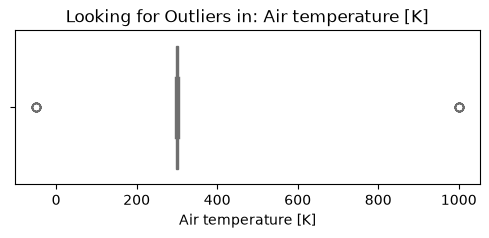

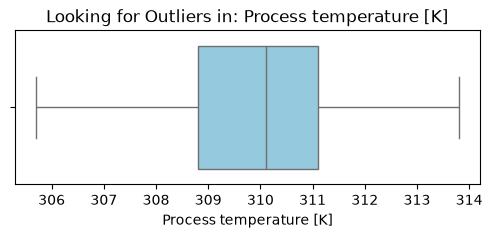

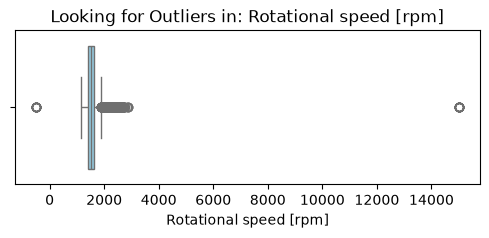

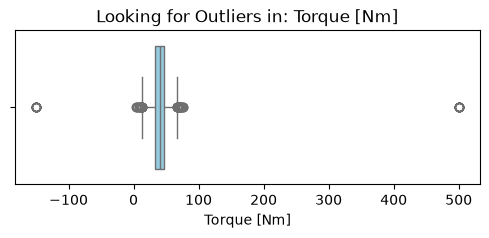

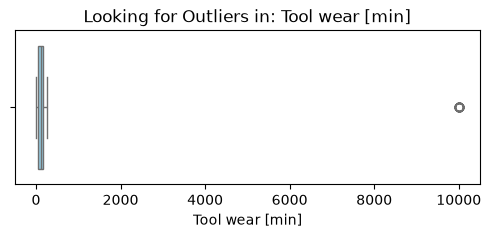

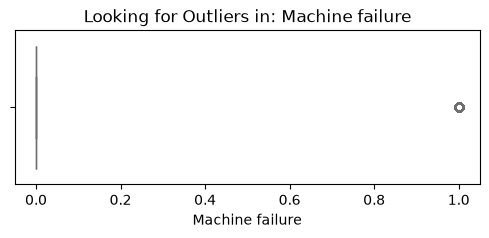

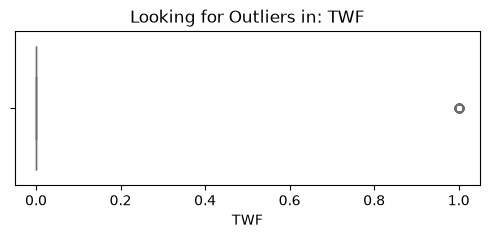

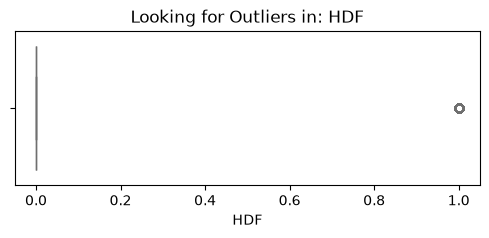

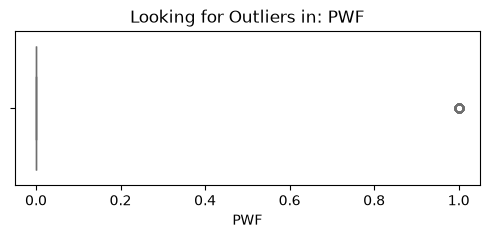

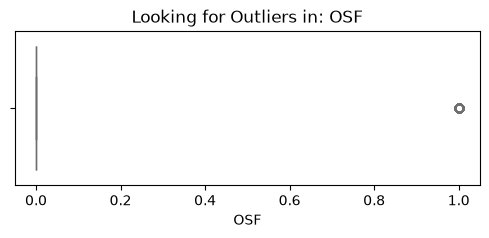

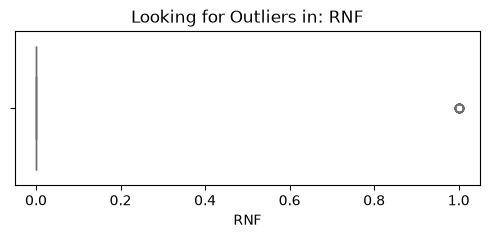

All boxplots saved successfully in: F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\figures


In [107]:
#find and making box plot for outlier of  numerical features
output_dir = r"F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\figures"
os.makedirs(output_dir, exist_ok=True)


num_cols = df.select_dtypes(include=['float64', 'int64']).columns
if 'UDI' in num_cols:
    num_cols = num_cols.drop('UDI')

for col in num_cols:
    plt.figure(figsize=(6, 2))
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Looking for Outliers in: {col}')
    
    # Sanitize column names for safe Windows file paths (removes brackets and spaces)
    safe_col_name = col.replace(" ", "_").replace("[", "").replace("]", "").replace("/", "_")
    file_path = os.path.join(output_dir, f"boxplot_{safe_col_name}.png")
    
    plt.savefig(file_path, bbox_inches='tight', dpi=300)
    plt.show()
    plt.close()

print(f"All boxplots saved successfully in: {output_dir}")

In [108]:
#finding outlier from each column
for col in num_cols:
    q1=df[col].quantile(0.25)
    q3=df[col].quantile(0.75)
    iqr=q3-q1
    lower=q1-1.5*iqr
    upper=q3+1.5*iqr
    outliers=df[(df[col]<lower)|(df[col]>upper)]
    if len(outliers) > 0:
        print(f"{col}: Found {len(outliers)} outliers.")
    else:
        print(f"{col}: No outliers.")

Air temperature [K]: Found 30 outliers.
Process temperature [K]: No outliers.
Rotational speed [rpm]: Found 447 outliers.
Torque [Nm]: Found 99 outliers.
Tool wear [min]: Found 30 outliers.
Machine failure: Found 343 outliers.
TWF: Found 46 outliers.
HDF: Found 117 outliers.
PWF: Found 96 outliers.
OSF: Found 99 outliers.
RNF: Found 20 outliers.


In [109]:
#defining place where we save our figures
output_dir = r"F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\figures"
os.makedirs(output_dir, exist_ok=True)

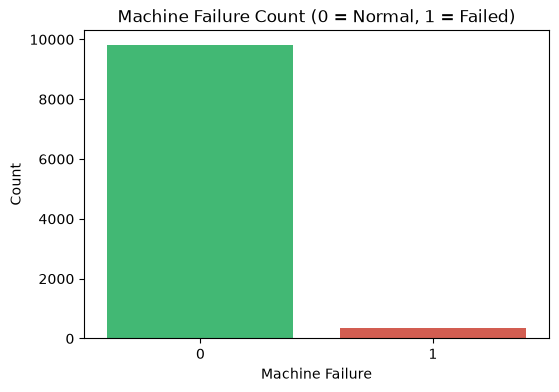

In [110]:
# target distribution plot
plt.figure(figsize=(6, 4))
sns.countplot(
    data=df,
    x='Machine failure',
    hue='Machine failure',
    palette=['#2ecc71', '#e74c3c'],
    legend=False,
)

plt.title('Machine Failure Count (0 = Normal, 1 = Failed)')
plt.xlabel('Machine Failure')
plt.ylabel('Count')

plt.savefig(
    os.path.join(output_dir, 'target_distribution.png'), bbox_inches='tight'
)
plt.show()
plt.close()

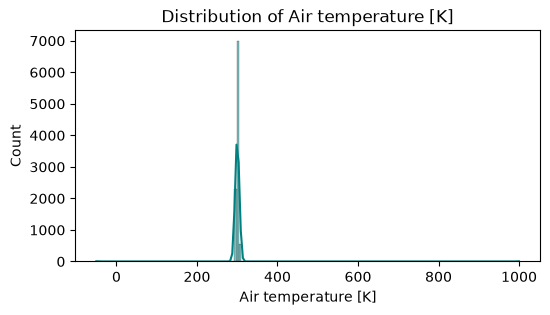

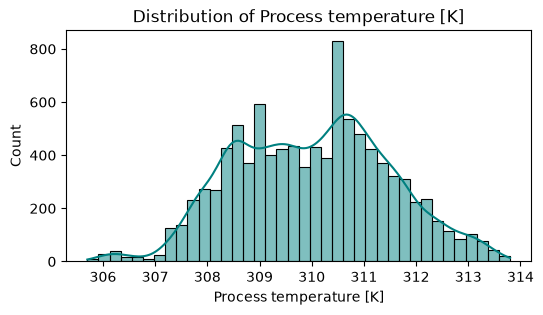

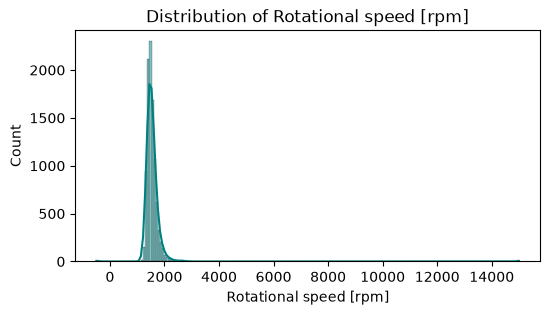

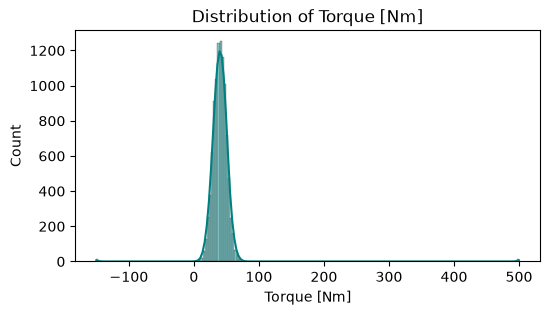

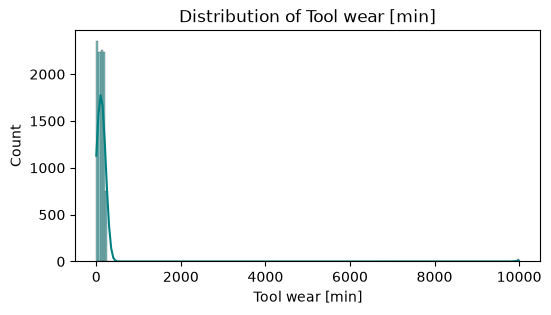

In [111]:
#Distribution Histograms (One Graph per Feature)
# List of main sensor columns
num_cols = [
    'Air temperature [K]', 
    'Process temperature [K]', 
    'Rotational speed [rpm]', 
    'Torque [Nm]', 
    'Tool wear [min]'
]

# Plot a simple histogram for each feature
for col in num_cols:
    plt.figure(figsize=(6, 3))
    sns.histplot(df[col], kde=True, color='teal')
    plt.title(f'Distribution of {col}')
    
    # Save image with safe filename
    clean_name = col.replace(" ", "_").replace("[", "").replace("]", "")
    plt.savefig(os.path.join(output_dir, f"hist_{clean_name}.png"), bbox_inches='tight')
    plt.show()
    plt.close()

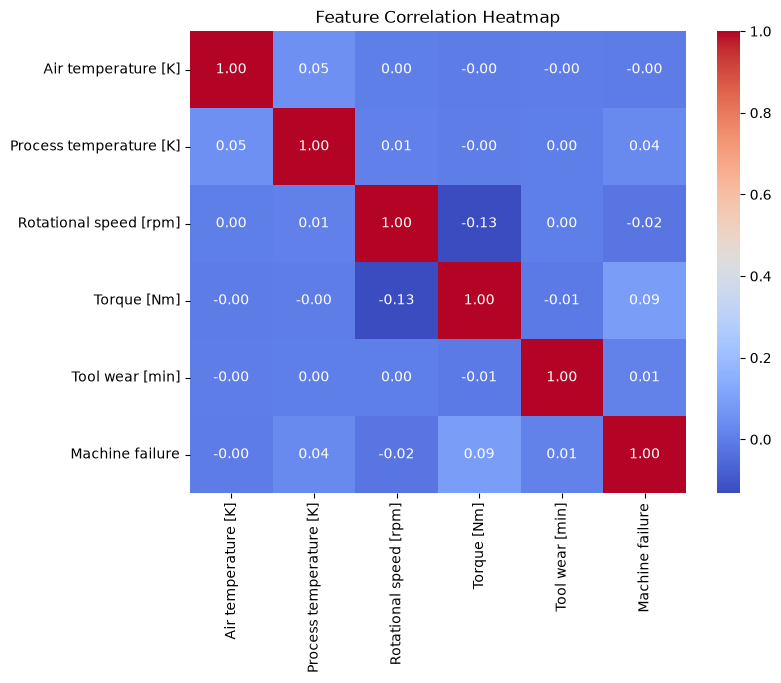

All graphs saved in: F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\figures


In [112]:
plt.figure(figsize=(8, 6))
fet_to_check=num_cols+['Machine failure']
sns.heatmap(df[fet_to_check].corr(),annot=True,cmap="coolwarm",fmt=".2f")
plt.title('Feature Correlation Heatmap')

# Save and display image
plt.savefig(os.path.join(output_dir, "correlation_heatmap.png"), bbox_inches='tight')
plt.show()
plt.close()

print(f"All graphs saved in: {output_dir}")

Data cleaning 

In [113]:
#removing duplicates
df=df.drop_duplicates().reset_index(drop=True)


In [114]:
#checking duplicates
print("number of duplicate rows:",df.duplicated().sum())

number of duplicate rows: 0


In [115]:
#Drop Non-Predictive Identifier Columns
cols_to_drop=['UDI', 'Product ID']
df=df.drop(columns=[col for col in cols_to_drop if col in df.columns])
print("Remaining columns:")
print(df.columns.tolist())

Remaining columns:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


In [116]:
#fill missing values
# 1.catagorical feature fill with mode
if 'Type' in df.columns and df['Type'].isnull().sum() > 0:
    type_mode = df['Type'].mode()[0]
    df['Type'] = df['Type'].fillna(type_mode)
    print(f"Imputed 'Type' missing values with mode: {type_mode}")
# Continuous Numerical Sensor feature
sensor_cols = [
    'Air temperature [K]', 
    'Process temperature [K]', 
    'Rotational speed [rpm]', 
    'Torque [Nm]', 
    'Tool wear [min]'
]
#numericic feature fill with median
for col in sensor_cols:
    if col in df.columns and df[col].isnull().sum() > 0:
        col_median = df[col].median()
        df[col] = df[col].fillna(col_median)
        print(f"Imputed '{col}' missing values with median: {col_median:.2f}")

Imputed 'Type' missing values with mode: L
Imputed 'Air temperature [K]' missing values with median: 300.10
Imputed 'Process temperature [K]' missing values with median: 310.10
Imputed 'Rotational speed [rpm]' missing values with median: 1503.00
Imputed 'Torque [Nm]' missing values with median: 40.10
Imputed 'Tool wear [min]' missing values with median: 108.00


In [117]:
#normalizing target variable
df['Machine failure'].value_counts()
df['Machine failure'].value_counts(normalize=True)

Machine failure
0    0.965999
1    0.034001
Name: proportion, dtype: float64

In [128]:
df['Machine failure'].value_counts()


Machine failure
0    9688
1     341
Name: count, dtype: int64

In [118]:
#checking missing 
df.isna().sum()

Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [119]:
continuous_cols = [
    'Air temperature [K]', 
    'Rotational speed [rpm]', 
    'Torque [Nm]', 
    'Tool wear [min]'
]
for col in continuous_cols:
    q1=df[col].quantile(0.25)
    q3=df[col].quantile(0.75)
    iqr=q3-q1
    upper=q3+1.5*iqr
    lower=q1-1.5*iqr
    df[col]=df[col].clip(lower=lower,upper=upper)
    print(f"Capped outliers for '{col}' between [{lower:.2f}, {upper:.2f}]")

Capped outliers for 'Air temperature [K]' between [293.75, 306.15]
Capped outliers for 'Rotational speed [rpm]' between [1153.00, 1881.00]
Capped outliers for 'Torque [Nm]' between [13.60, 66.40]
Capped outliers for 'Tool wear [min]' between [-104.00, 320.00]


In [120]:
#checking is any outlier remain or not
continuous_cols = [
    'Air temperature [K]', 
    'Process temperature [K]', 
    'Rotational speed [rpm]', 
    'Torque [Nm]', 
    'Tool wear [min]'
]

print(" Re-checking Outliers After Capping ")

for col in continuous_cols:
    if col in df.columns:
        # Calculate IQR
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        
        lower_fence = Q1 - 1.5 * IQR
        upper_fence = Q3 + 1.5 * IQR
        
        #  remaining outliers
        outliers = df[(df[col] < lower_fence) | (df[col] > upper_fence)]
        print(f"{col}: {len(outliers)} outliers remaining.")
        

 Re-checking Outliers After Capping 
Air temperature [K]: 0 outliers remaining.
Process temperature [K]: 1 outliers remaining.
Rotational speed [rpm]: 0 outliers remaining.
Torque [Nm]: 0 outliers remaining.
Tool wear [min]: 0 outliers remaining.


In [121]:
# adjustment for tool wear because it can neaver be negitive
df['Tool wear [min]'] = df['Tool wear [min]'].clip(lower=0, upper=320.00)

In [122]:
import os

#saving clean data set to desired location
processed_dir = r"F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\data\processed"
file_name = "ai4i2020_cleaned.csv"
output_path = os.path.join(processed_dir, file_name)

os.makedirs(processed_dir, exist_ok=True)

# 2. Save the DataFrame to CSV 
df.to_csv(output_path, index=False)

print(f"Dataset successfully saved to:\n{output_path}")



Dataset successfully saved to:
F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\data\processed\ai4i2020_cleaned.csv


Feature Engineering

In [123]:
#checking number of rows for each flag coloumn
failure_modes=['TWF','HDF','PWF','OSF', 'RNF']
df[failure_modes].sum()

TWF     46
HDF    116
PWF     95
OSF     99
RNF     19
dtype: int64

In [124]:
#Machine failure is simply the sum of these flags
#so keeping them will deduct or reduce out model performance so drop it
data = df.drop(columns=['TWF', 'HDF', 'PWF', 'OSF', 'RNF'])


In [125]:
data2=data.copy()


# Physics-Based Domain Features specification
# 1.ΔT:Temperature Difference -> Drives Heat Dissipation Failure (HDF)
data2['Temp_diff'] = (
    data2['Process temperature [K]'] - data2['Air temperature [K]']
)

# 2.P: Mechanical Power in Watts -> Drives Power Failure (PWF)
data2['Power'] = data['Torque [Nm]'] * (
    data2['Rotational speed [rpm]'] * (2 * np.pi / 60)
)

#3. Overstrain Index: Strain = Tool Wear x Torque -> Drives Overstrain Failure (OSF)
data2['Overstrain_Index'] = data2['Tool wear [min]'] * data['Torque [Nm]']

#4. Load Severity Ratio
data2['Torque_Speed_Ratio'] = data2['Torque [Nm]'] / (
    data2['Rotational speed [rpm]'] + 1e-5
)



In [126]:
# 1. One-hot encode product type ('L', 'M', 'H')
data2= pd.get_dummies(data, columns=['Type'], drop_first=True)

# 2. Convert boolean flags to integers (0 and 1)
if 'Type_L' in data2.columns:
  data2['Type_L'] = data2['Type_L'].astype(int)
if 'Type_M' in data2.columns:
  data2['Type_M'] = data2['Type_M'].astype(int)

# 3. Save engineered dataset
processed_dir = r"F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\data\processed"
output_file = os.path.join(processed_dir, "ai4i2020_engineered.csv")
os.makedirs(processed_dir, exist_ok=True)

data2.to_csv(output_file, index=False)

data2.head()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,Type_L,Type_M
0,298.1,308.6,1551.0,42.8,0.0,0,0,1
1,298.2,308.7,1408.0,46.3,3.0,0,1,0
2,298.1,308.5,1498.0,49.4,5.0,0,1,0
3,298.2,308.6,1433.0,39.5,7.0,0,1,0
4,298.2,308.7,1408.0,40.0,9.0,0,1,0


In [127]:
data2.columns.tolist()

['Air temperature [K]',
 'Process temperature [K]',
 'Rotational speed [rpm]',
 'Torque [Nm]',
 'Tool wear [min]',
 'Machine failure',
 'Type_L',
 'Type_M']

Train test split

In [131]:
# Separating  predictors X and target Y
df2=data2.copy()
target_col = 'Machine failure'
X = df2.drop(columns=[target_col])
y = df2[target_col]

# Performing  Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Train-Test Split info")
print(f"X_train shape: {X_train.shape} ")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape : {X_test.shape}") 
print(f"y_test shape : {y_test.shape}")
print(f"\nTrain failure rate: {y_train.mean()*100:.2f}%")
print(f"Test failure rate : {y_test.mean()*100:.2f}%")

Train-Test Split info
X_train shape: (8023, 7) 
y_train shape: (8023,)
X_test shape : (2006, 7)
y_test shape : (2006,)

Train failure rate: 3.40%
Test failure rate : 3.39%


In [132]:
# 1. Define target directory
processed_dir = r"F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\tables"
os.makedirs(processed_dir, exist_ok=True)

# Export train and test sets to CSV 
X_train.to_csv(os.path.join(processed_dir, "X_train.csv"), index=False)
y_train.to_csv(os.path.join(processed_dir, "y_train.csv"), index=False)
X_test.to_csv(os.path.join(processed_dir, "X_test.csv"), index=False)
y_test.to_csv(os.path.join(processed_dir, "y_test.csv"), index=False)

print("Train and test splits saved successfully!")
print(f"Saved directory: {processed_dir}\n")

# verification check
files = ["X_train.csv", "y_train.csv", "X_test.csv", "y_test.csv"]
for file in files:
    file_path = os.path.join(processed_dir, file)
    size_kb = os.path.getsize(file_path) / 1024
    print(f" - {file:<12}: {size_kb:.2f} KB")

Train and test splits saved successfully!
Saved directory: F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\tables

 - X_train.csv : 271.32 KB
 - y_train.csv : 23.52 KB
 - X_test.csv  : 67.91 KB
 - y_test.csv  : 5.89 KB


In [135]:
X_train

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_L,Type_M
5260,303.5,313.0,1492.0,46.1,89.0,0,1
2321,299.2,308.8,1503.0,52.5,193.0,0,1
1015,296.2,307.2,1356.0,43.6,22.0,1,0
8198,299.3,310.7,1374.0,48.9,222.0,0,1
374,297.4,308.3,1431.0,40.1,113.0,1,0
...,...,...,...,...,...,...,...
2236,299.3,308.5,1422.0,43.1,186.0,0,1
8369,298.8,309.7,1503.0,20.6,25.0,1,0
4850,303.5,312.0,1441.0,56.8,88.0,1,0
7676,300.6,311.7,1448.0,49.1,206.0,1,0


Feature Scaling

In [133]:
from sklearn.preprocessing import StandardScaler
binary_cols = ['Type_L', 'Type_M']
continue_cols=[cols for cols in X_train.columns if cols not in binary_cols]
scaler=StandardScaler()
X_train_scaled=X_train.copy()
X_test_scaled=X_test.copy()
X_train_scaled[continue_cols]=scaler.fit_transform(X_train_scaled[continue_cols])
X_test_scaled[continue_cols]=scaler.transform(X_test_scaled[continue_cols])

In [134]:
# 5. Save scaled CSV files to processed folder
X_train_scaled.to_csv(
    r"F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\tables\X_train_scaled.csv",
    index=False,
)
X_test_scaled.to_csv(
    r"F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\tables\X_test_scaled.csv",
    index=False,
)

print("✓ Feature scaling complete!")
X_train_scaled.head()

✓ Feature scaling complete!


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_L,Type_M
5260,1.760654,2.054134,-0.248781,0.612469,-0.313597,0,1
2321,-0.404170,-0.827544,-0.173757,1.256896,1.327539,0,1
1015,-1.914512,-1.925326,-1.176357,0.360740,-1.370867,1,0
8198,-0.353825,0.476072,-1.053590,0.894406,1.785163,0,1
374,-1.310375,-1.170601,-0.664826,0.008318,0.065127,1,0


Model_training 

In [137]:
#implementing logistic regression
model_lg=LogisticRegression(class_weight='balanced',random_state=42,max_iter=1000)
model_lg.fit(X_train_scaled,y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [143]:
#implmenting random forest model
from sklearn.ensemble import RandomForestClassifier
rf_model=RandomForestClassifier(class_weight='balanced',random_state=42,
    n_estimators=200,max_depth=10,
    n_jobs=-1
)
rf_model.fit(X_train_scaled,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_feat

In [144]:
#xgbost implementation
from xgboost import XGBClassifier

# Convert to NumPy arrays
X_train_xgb = X_train_scaled.to_numpy()
X_test_xgb = X_test_scaled.to_numpy()

# Calculate class imbalance
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# Create XGBoost model
model_xg = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric="logloss"
)

# Train XGBoost
model_xg.fit(X_train_xgb, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


prediction and evaluation

In [154]:
#Prediction and evaluation of logistic regression
y_pred_lg = model_lg.predict(X_test_scaled)
y_proba_lg = model_lg.predict_proba(X_test_scaled)[:, 1]
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lg))
print()
print("Classification Report:")
print(classification_report(y_test, y_pred_lg))
print()
print("ROC-AUC:", roc_auc_score(y_test, y_proba))

Confusion Matrix:
[[1433  505]
 [  17   51]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.74      0.85      1938
           1       0.09      0.75      0.16        68

    accuracy                           0.74      2006
   macro avg       0.54      0.74      0.50      2006
weighted avg       0.96      0.74      0.82      2006


ROC-AUC: 0.8060310811631154


In [155]:
#random forest prediction and evaluation
y_pred_rf=rf_model.predict(X_test_scaled)
y_prob_rf=rf_model.predict_proba(X_test_scaled)[:, 1]
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))
print()
print("Classification Report:")
print(classification_report(y_test, y_pred))
print()
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

Confusion Matrix:
[[1895   43]
 [  19   49]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      1938
           1       0.53      0.72      0.61        68

    accuracy                           0.97      2006
   macro avg       0.76      0.85      0.80      2006
weighted avg       0.97      0.97      0.97      2006


ROC-AUC: 0.9651778668123596


In [151]:
y_pred_xgb = model_xg.predict(X_test_scaled)
y_proba_xgb = model_xg.predict_proba(X_test_scaled)[:, 1]

print("Confusion Matrix")
print(confusion_matrix(y_test, y_pred_xgb))
print()
print("Classification Report:")
print(classification_report(y_test, y_pred_xgb))
print()
print("ROC-AUC:", roc_auc_score(y_test, y_proba_xgb))

Confusion Matrix
[[1910   28]
 [  19   49]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1938
           1       0.64      0.72      0.68        68

    accuracy                           0.98      2006
   macro avg       0.81      0.85      0.83      2006
weighted avg       0.98      0.98      0.98      2006


ROC-AUC: 0.9682890183937352


In [156]:
#roc acuracy score comparision
print(roc_auc_score(y_test, y_proba))       # Logistic Regression
print(roc_auc_score(y_test, y_prob_rf))    # Random Forest
print(roc_auc_score(y_test, y_proba_xgb))   # XGBoost

0.8060310811631154
0.9651778668123596
0.9682890183937352


In [157]:
#saving model comparision csv
# Define table output path
table_dir = r"F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\table"
os.makedirs(table_dir, exist_ok=True)

# comparision
comparison_data = [
    {
        "Model": "Logistic Regression",
        "Precision": 0.09,
        "Recall": 0.75,
        "F1-Score": 0.16,
        "ROC-AUC": 0.806,
        "False Positives": 505,
        "False Negatives": 17,
    },
    {
        "Model": "Random Forest",
        "Precision": 0.53,
        "Recall": 0.72,
        "F1-Score": 0.61,
        "ROC-AUC": 0.965,
        "False Positives": 43,
        "False Negatives": 19,
    },
    {
        "Model": "XGBoost",
        "Precision": 0.64,
        "Recall": 0.72,
        "F1-Score": 0.68,
        "ROC-AUC": 0.968,
        "False Positives": 28,
        "False Negatives": 19,
    },
]

comparison_df = pd.DataFrame(comparison_data)
csv_save_path = os.path.join(table_dir, "model_comparison.csv")
comparison_df.to_csv(csv_save_path, index=False)

print(f" Model evaluation table saved to:\n{csv_save_path}")
display(comparison_df)

 Model evaluation table saved to:
F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\table\model_comparison.csv


,Model,Precision,Recall,F1-Score,ROC-AUC,False Positives,False Negatives
0,Logistic Regression,0.09,0.75,0.16,0.806,505,17
1,Random Forest,0.53,0.72,0.61,0.965,43,19
2,XGBoost,0.64,0.72,0.68,0.968,28,19


In [159]:
import os
import joblib


models_dir = r"F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\models"
os.makedirs(models_dir, exist_ok=True)

# Save XGBoost one which hase high acuracy
best_model_path = os.path.join(models_dir, "xgb_model.joblib")
joblib.dump(model_xg, best_model_path)

print(f" XGBoost model saved successfully to:\n{best_model_path}")

 XGBoost model saved successfully to:
F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\models\xgb_model.joblib


In [160]:
#this model can perform well but we can increase acuracy even more using hyper parameter tunning

Hyper Parameter Tunning:

In [164]:
#remove extra braces
import re

def clean_col(col):
    return re.sub(r'[\[\]<>]', '', col)

X_train_scaled.columns = [clean_col(c) for c in X_train_scaled.columns]

X_test_scaled.columns = [clean_col(c) for c in X_test_scaled.columns]

print(X_train_scaled.columns.tolist())

['Air temperature K', 'Process temperature K', 'Rotational speed rpm', 'Torque Nm', 'Tool wear min', 'Type_L', 'Type_M']


In [166]:
# 1. Setup parameter grid
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7, 9],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0],
    'scale_pos_weight': [1, 5, 10, 15],  
}

# intilize base model XGBoost 
base_xgb = XGBClassifier(random_state=42, eval_metric='logloss')

# applying RandomizedSearchCV with 5-Fold Stratified CV
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search = RandomizedSearchCV(
    estimator=base_xgb,
    param_distributions=param_grid,
    n_iter=15,  
    scoring='f1',
    cv=skf,
    random_state=42,
    n_jobs=-1,
)
print("running random search cv")
search.fit(X_train_scaled, y_train)
print("Best Parameters:", search.best_params_)
print("Best F1 Score (CV):", search.best_score_)

running random search cv
Best Parameters: {'subsample': 1.0, 'scale_pos_weight': 10, 'n_estimators': 300, 'max_depth': 9, 'learning_rate': 0.2, 'colsample_bytree': 1.0}
Best F1 Score (CV): 0.6797750333652519


In [167]:
best_xgb =search.best_estimator_

y_pred_best = best_xgb.predict(X_test_scaled)
y_proba_best = best_xgb.predict_proba(X_test_scaled)[:, 1]

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_best))
print()
print("Classification Report:")
print(classification_report(y_test, y_pred_best))
print()
print("ROC-AUC:", roc_auc_score(y_test, y_proba_best))

Confusion Matrix:
[[1924   14]
 [  23   45]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1938
           1       0.76      0.66      0.71        68

    accuracy                           0.98      2006
   macro avg       0.88      0.83      0.85      2006
weighted avg       0.98      0.98      0.98      2006


ROC-AUC: 0.9736614460025497


In [170]:
# Final evaluation comparison dataset
table_dir = r'F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\table'
os.makedirs(table_dir, exist_ok=True)


final_comparison = [
    {
        'Model': 'Logistic Regression',
        'Precision': 0.09,
        'Recall': 0.75,
        'F1-Score': 0.16,
        'ROC-AUC': 0.8060,
        'False Positives': 505,
        'False Negatives': 17,
    },
    {
        'Model': 'Random Forest',
        'Precision': 0.53,
        'Recall': 0.72,
        'F1-Score': 0.61,
        'ROC-AUC': 0.9652,
        'False Positives': 43,
        'False Negatives': 19,
    },
    {
        'Model': 'XGBoost (Baseline)',
        'Precision': 0.64,
        'Recall': 0.72,
        'F1-Score': 0.68,
        'ROC-AUC': 0.9683,
        'False Positives': 28,
        'False Negatives': 19,
    },
    {
        'Model': 'XGBoost (Tuned)',
        'Precision': 0.76,
        'Recall': 0.66,
        'F1-Score': 0.71,
        'ROC-AUC': 0.9737,
        'False Positives': 14,
        'False Negatives': 23,
    },
]

df_comparison = pd.DataFrame(final_comparison)
save_path = os.path.join(table_dir, 'final_model_comparison.csv')
df_comparison.to_csv(save_path, index=False)

print(f'✓ Final model comparison table saved to:\n{save_path}')
display(df_comparison)

✓ Final model comparison table saved to:
F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\table\final_model_comparison.csv


,Model,Precision,Recall,F1-Score,ROC-AUC,False Positives,False Negatives
0,Logistic Regression,0.09,0.75,0.16,0.8060,505,17
1,Random Forest,0.53,0.72,0.61,0.9652,43,19
2,XGBoost (Baseline),0.64,0.72,0.68,0.9683,28,19
3,XGBoost (Tuned),0.76,0.66,0.71,0.9737,14,23


In [171]:
#so xg bost tunned is best model here

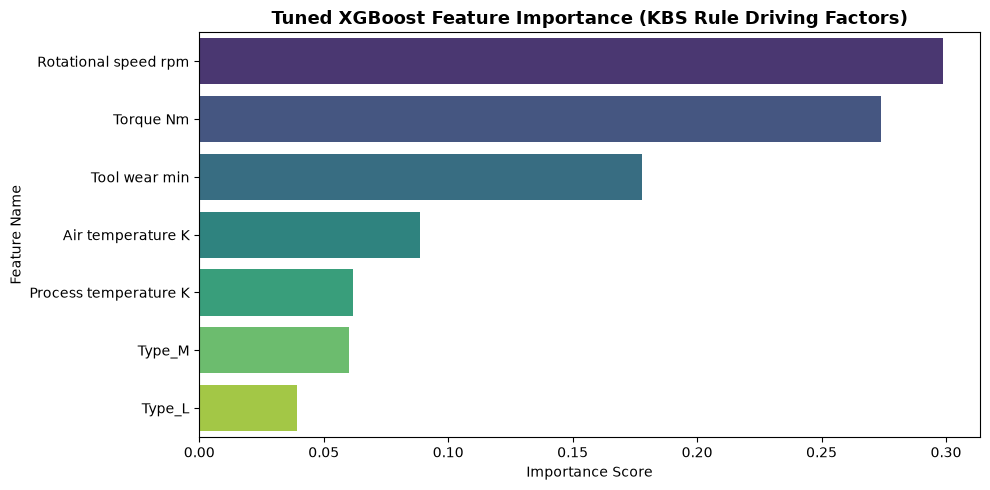

✓ Feature importance chart saved to:
F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\figures\xgb_tuned_feature_importance.png



,Feature,Importance
0,Rotational speed rpm,0.298717
1,Torque Nm,0.273971
2,Tool wear min,0.177918
3,Air temperature K,0.088482
4,Process temperature K,0.061629
5,Type_M,0.060005
6,Type_L,0.039278


In [172]:
# Extract feature importances
importances = best_xgb.feature_importances_
feature_names = X_train_scaled.columns

importance_df = (
    pd.DataFrame({'Feature': feature_names, 'Importance': importances})
    .sort_values(by='Importance', ascending=False)
    .reset_index(drop=True)
)

# Plot feature importance bar chart
plt.figure(figsize=(10, 5))
sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature',
    palette='viridis',
    hue='Feature',
    legend=False,
)
plt.title(
    'Tuned XGBoost Feature Importance (KBS Rule Driving Factors)',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel('Importance Score')
plt.ylabel('Feature Name')
plt.tight_layout()

# Export plot
fig_dir = r'F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\figures'
os.makedirs(fig_dir, exist_ok=True)
fig_path = os.path.join(fig_dir, 'xgb_tuned_feature_importance.png')

plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

print(f'✓ Feature importance chart saved to:\n{fig_path}\n')
display(importance_df)

In [173]:
#saving all pickel files or artifacts inside model folder
models_dir = r"F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\models"
os.makedirs(models_dir, exist_ok=True)
joblib.dump(scaler, os.path.join(models_dir, "scaler.joblib"))
joblib.dump(best_xgb, os.path.join(models_dir, "best_xgb_tuned.joblib"))
feature_names = list(X_train_scaled.columns)
joblib.dump(feature_names, os.path.join(models_dir, "feature_names.joblib"))

print(" All model artifacts saved successfully in the 'models' folder")

 All model artifacts saved successfully in the 'models' folder
